In [1]:
import math, os, time
from collections import defaultdict
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

In [2]:
SUPPORT      = 0.001   # minimum support
MIN_CONF     = 0.05    # minimum confidence of a rule
MIN_LIFT     = 1.0     # minimum lift (1.0 = discards uninteresting rules)
TOP_K        = 10      # how many songs to recommend
EVAL_USERS   = 5000    # test users for evaluation
SEED         = 0

NPZ = "data/filtered_100_10.npz"

In [3]:
d = np.load(NPZ)
#print("keys from .npz:", d.files)
USER_KEY = next(k for k in ("user", "users", "new_user") if k in d.files)
#print("key from users:", USER_KEY)

_, user_idx = np.unique(d[USER_KEY], return_inverse=True) # users
n_songs = len(d["old_song"])
X = sp.csr_matrix((np.ones(len(user_idx), dtype=np.int8), (user_idx, d["song"])),
                  shape=(user_idx.max() + 1, n_songs))
X.sum_duplicates()

print(f"users (baskets): {X.shape[0]:,} | songs (items): {X.shape[1]:,} | interactions: {X.nnz:,}")

users (baskets): 956,770 | songs (items): 64,519 | interactions: 42,038,519


In [4]:
def iter_baskets(X):
    ind, ptr = X.indices, X.indptr
    for u in range(X.shape[0]):
        yield ind[ptr[u]:ptr[u + 1]]

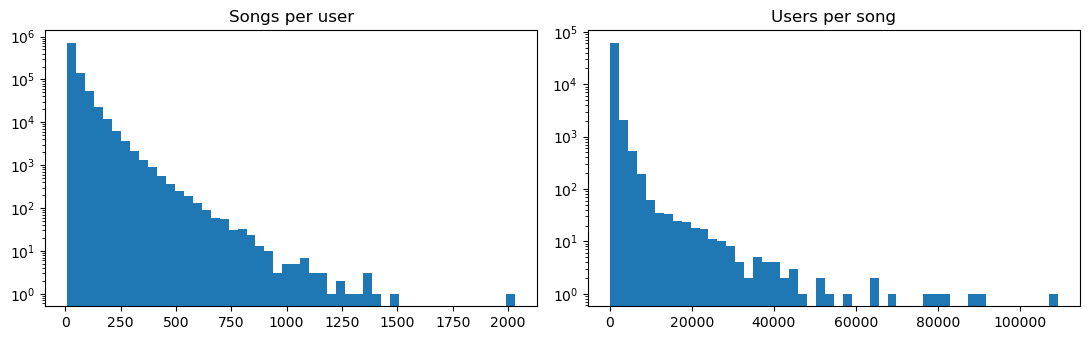

songs per user: median 26, max 2032
users per song:  median 269, max 109074


In [5]:
basket_sizes = np.diff(X.indptr)
item_counts_all = np.bincount(X.indices, minlength=X.shape[1])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(basket_sizes, bins=50); ax[0].set_title("Songs per user"); ax[0].set_yscale("log")
ax[1].hist(item_counts_all[item_counts_all > 0], bins=50); ax[1].set_title("Users per song"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

print(f"songs per user: median {np.median(basket_sizes):.0f}, max {basket_sizes.max()}")
print(f"users per song:  median {np.median(item_counts_all[item_counts_all > 0]):.0f}, max {item_counts_all.max()}")

In [6]:
def pass1_items(X, s_count):
    counts = np.bincount(X.indices, minlength=X.shape[1])
    freq = np.flatnonzero(counts >= s_count)
    table = np.zeros(X.shape[1], dtype=np.int32)                    # 0 = not frequent
    table[freq] = np.arange(1, len(freq) + 1, dtype=np.int32)
    return counts, freq, table

n_baskets = X.shape[0]
s_count = math.ceil(SUPPORT * n_baskets)
counts, freq, table = pass1_items(X, s_count)
m = len(freq)

print(f"support {SUPPORT} sobre {n_baskets:,} usuarios -> mínimo {s_count} usuarios")
print(f"songs frequent: {m:,} of {X.shape[1]:,}")
print(f"possible pairs between them: {m * (m - 1) // 2:,}  (upper triangular matrix of {m * (m - 1) // 2 * 4 / 1e6:,.0f} MB)")

support 0.001 sobre 956,770 usuarios -> mínimo 957 usuarios
songs frequent: 9,192 of 64,519
possible pairs between them: 42,241,836  (upper triangular matrix of 169 MB)


In [7]:
def pass2_pairs(X, table, m, s_count, method="triangular", max_gb=1.0):
    size = m * (m - 1) // 2
    use_tri = method == "triangular" and size * 4 / 1e9 <= max_gb
    print("method:", "upper triangular matrix" if use_tri else "triples")
    if use_tri:
        counts = np.zeros(size, dtype=np.int32)
    else:
        triples, buf, buf_n = {}, [], 0

    def flush():
        nonlocal buf, buf_n
        if buf:
            keys, c = np.unique(np.concatenate(buf), return_counts=True)
            for key, cnt in zip(keys.tolist(), c.tolist()):
                triples[key] = triples.get(key, 0) + cnt
        buf, buf_n = [], 0

    tri_cache = {}
    for items in iter_baskets(X):
        b = table[items]
        b = np.sort(b[b > 0]) - 1
        L = len(b)
        if L < 2:
            continue
        if L not in tri_cache:
            tri_cache[L] = np.triu_indices(L, 1)
            if L > 200:
                tri_cache.pop(L)
        I, J = tri_cache.get(L) or np.triu_indices(L, 1)
        ii, jj = b[I].astype(np.int64), b[J].astype(np.int64)
        if use_tri:
            counts[ii * m - ii * (ii + 1) // 2 + (jj - ii - 1)] += 1
        else:
            buf.append(ii * m + jj); buf_n += len(ii)
            if buf_n > 5_000_000:
                flush()

    if use_tri:
        ks = np.flatnonzero(counts >= s_count)
        rows = np.arange(m, dtype=np.int64)
        starts = rows * m - rows * (rows + 1) // 2
        i = np.searchsorted(starts, ks, side="right") - 1
        j = ks - starts[i] + i + 1
        return i, j, counts[ks]
    flush()
    keys = np.array([k for k, v in triples.items() if v >= s_count], dtype=np.int64)
    c = np.array([triples[k] for k in keys.tolist()], dtype=np.int64)
    return keys // m, keys % m, c

t0 = time.time()
pi, pj, pc = pass2_pairs(X, table, m, s_count)
print(f"frequent pairs: {len(pc):,}  ({time.time() - t0:.1f} s)")

method: upper triangular matrix
frequent pairs: 38,786  (67.6 s)


In [8]:
# top 10 most frequent pairs
top = np.argsort(-pc)[:10]
pd.DataFrame({"song_1": freq[pi[top]], "song_2": freq[pj[top]], "users with both": pc[top],
              "support": pc[top] / n_baskets})

,song_1,song_2,users with both,support
0,162,165,50670,0.052959
1,162,181,48110,0.050284
2,17,163,42726,0.044657
3,17,177,42294,0.044205
4,165,181,42067,0.043968
5,163,177,37993,0.039710
6,162,169,33786,0.035313
7,17,176,33580,0.035097
8,17,168,32762,0.034242
9,165,169,30821,0.032214


In [9]:
itemsets = {(int(s),): int(counts[s]) for s in freq}
level = {(a, b): c for a, b, c in zip(pi.tolist(), pj.tolist(), pc.tolist())}
for t, c in level.items():
    itemsets[(int(freq[t[0]]), int(freq[t[1]]))] = c
    
pd.Series(pd.Series([len(t) for t in itemsets]).value_counts().sort_index(), name="itemsets frecuentes")

1     9192
2    38786
Name: itemsets frecuentes, dtype: int64

In [10]:
def make_rules(itemsets, n, min_conf, min_lift):
    rows = []
    for iset, c in itemsets.items():
        if len(iset) < 2:
            continue
        for j in iset:
            ant = tuple(x for x in iset if x != j)
            conf = c / itemsets[ant]
            sup_j = itemsets[(j,)] / n
            lift = conf / sup_j
            if conf >= min_conf and lift >= min_lift:
                rows.append((ant, j, c / n, conf, lift, conf - sup_j))
    return pd.DataFrame(rows, columns=["antecedent", "consequent", "support", "confidence", "lift", "interest"])

rules = make_rules(itemsets, n_baskets, MIN_CONF, MIN_LIFT)
print(f"{len(rules):,} rules with confidence ≥ {MIN_CONF} and lift ≥ {MIN_LIFT}")
rules.sort_values("lift", ascending=False).head(10)

69,985 rules with confidence ≥ 0.05 and lift ≥ 1.0


,antecedent,consequent,support,confidence,lift,interest
69984,"(42336,)",42342,0.001063,0.872213,618.611518,0.870803
69983,"(42342,)",42336,0.001063,0.753892,618.611518,0.752673
67652,"(7328,)",7329,0.001035,0.801619,607.738055,0.800300
67651,"(7329,)",7328,0.001035,0.784469,607.738055,0.783178
69153,"(36556,)",13053,0.001019,0.680866,552.998377,0.679635
69154,"(13053,)",36556,0.001019,0.827674,552.998377,0.826177
68578,"(9542,)",32218,0.001024,0.721649,542.808630,0.720320
68577,"(32218,)",9542,0.001024,0.770440,542.808630,0.769021
68758,"(10411,)",11761,0.001229,0.783478,539.286289,0.782025
68757,"(11761,)",10411,0.001229,0.846043,539.286289,0.844474


In [11]:
ant_songs = np.unique([a[0] for a in rules["antecedent"] if len(a) == 1])
has_rule = np.zeros(X.shape[1], dtype=np.int32)
has_rule[ant_songs] = 1
covered = (X @ has_rule) > 0        # dothey have at least one song that is an antecedent of a rule?

print(f"users with at least one applicable rule: {covered.mean():.1%}  ({covered.sum():,} of {X.shape[0]:,})")

users with at least one applicable rule: 96.6%  (924,403 of 956,770)


In [12]:
# recommending
class Recommender:
    def __init__(self, rules, n_songs):
        self.n_songs = n_songs
        size = rules["antecedent"].map(len).to_numpy()
        s = rules[size == 1]                                          # rules with 1 song in antecedent
        a0 = np.array([a[0] for a in s["antecedent"]], dtype=np.int64)
        cons = s["consequent"].to_numpy(np.int64)
        conf = s["confidence"].to_numpy(np.float32)
        order = np.argsort(a0, kind="stable")
        a0, cons, conf = a0[order], cons[order], conf[order]
        keys, start = np.unique(a0, return_index=True)
        end = np.append(start[1:], len(a0))
        self.single = {int(k): (cons[a:b], conf[a:b]) for k, a, b in zip(keys, start, end)}
        mu = rules[size > 1]                                          # rules with 2+ songs
        self.m_ant, self.m_cons, self.m_conf = mu["antecedent"].tolist(), mu["consequent"].tolist(), mu["confidence"].tolist()
        self.by_item = defaultdict(list)
        for r, ant in enumerate(self.m_ant):
            for x in ant:
                self.by_item[x].append(r)

    def recommend(self, basket, k=10):
        S = set(np.asarray(basket).tolist())
        scores = np.zeros(self.n_songs, dtype=np.float32)
        for x in S:
            if x in self.single:
                c, w = self.single[x]
                scores[c] += w
        seen = set()
        for x in S:
            for r in self.by_item.get(x, ()):
                if r not in seen:
                    seen.add(r)
                    if all(a in S for a in self.m_ant[r]):
                        scores[self.m_cons[r]] += self.m_conf[r]
        if S:
            scores[list(S)] = 0                                       # not recommending what they already have
        k = min(k, self.n_songs - 1)
        top = np.argpartition(-scores, k)[:k]
        top = top[np.argsort(-scores[top])]
        return [(int(t), float(scores[t])) for t in top if scores[t] > 0]

rec = Recommender(rules, X.shape[1])

In [13]:
u = int(np.argmax(basket_sizes >= 20))
basket = X.indices[X.indptr[u]:X.indptr[u + 1]]
print(f"user {u} has {len(basket)} songs: {sorted(basket.tolist())[:15]} ...")
print("\nrecommendations (song, score):")
for song, score in rec.recommend(basket, TOP_K):
    print(f"  {song:>7}   {score:.3f}")

user 0 has 81 songs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] ...

recommendations (song, score):
      135   3.130
      163   2.652
      461   2.275
     4039   2.230
      181   2.198
     1190   2.147
      177   2.084
     4045   1.937
     1574   1.911
     1105   1.873


In [14]:
def mine(X_train):
    n = X_train.shape[0]
    s = math.ceil(SUPPORT * n)
    cnt, fq, tb = pass1_items(X_train, s)
    mm = len(fq)
    its = {(int(x),): int(cnt[x]) for x in fq}
    a, b, c = pass2_pairs(X_train, tb, mm, s)
    lvl = {(i, j): cc for i, j, cc in zip(a.tolist(), b.tolist(), c.tolist())}
    for t, cc in lvl.items():
        its[(int(fq[t[0]]), int(fq[t[1]]))] = cc
    return make_rules(its, n, MIN_CONF, MIN_LIFT), fq, its

rng = np.random.default_rng(SEED)
perm = rng.permutation(X.shape[0])
n_test = int(len(perm) * 0.2)
test_users, train_users = perm[:n_test], perm[n_test:]

rules_tr, freq_tr, its_tr = mine(X[train_users])
rec_tr = Recommender(rules_tr, X.shape[1])
print(f"rules learned with 80 % of users: {len(rules_tr):,}")

method: upper triangular matrix
rules learned with 80 % of users: 69,511


In [15]:
is_freq = np.zeros(X.shape[1], dtype=bool); is_freq[freq_tr] = True
popular = freq_tr[np.argsort(-np.array([its_tr[(int(s),)] for s in freq_tr]))][:TOP_K + 200]

hits = pop_hits = total = 0
for u in test_users:
    songs = X.indices[X.indptr[u]:X.indptr[u + 1]]
    cand = songs[is_freq[songs]]
    if len(songs) < 5 or len(cand) == 0:
        continue
    hidden = int(rng.choice(cand)) # hidden song
    basket = songs[songs != hidden]
    total += 1
    hits += hidden in [s for s, _ in rec_tr.recommend(basket, TOP_K)]
    have = set(basket.tolist())
    pop_hits += hidden in [int(p) for p in popular if int(p) not in have][:TOP_K]
    if total >= EVAL_USERS:
        break

print(f"Hit@{TOP_K} over {total:,} test users")
print(f"  A-Priori:   {hits / total:.3f}")
print(f"  Popular:    {pop_hits / total:.3f}")

Hit@10 over 5,000 test users
  A-Priori:   0.143
  Popular:    0.045
